## 01-Classical and Transformer Hybrid
In this notebook, we will try a hybrid option to combine Tfidf with transformer-based embedding model.

In [1]:
# !pip install sentence-transformers

In [2]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import precision_recall_fscore_support, f1_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sentence_transformers import SentenceTransformer

In [3]:
# train_fname = "../data/splits/train.csv"
# dev_fname = "../data/splits/dev.csv"

# new - load 50/50 splits
train_fname = "../../data/splits/train_50pc.csv"
dev_fname = "../../data/splits/dev_50pc.csv"

train_df = pd.read_csv(train_fname)
dev_df = pd.read_csv(dev_fname)

print("Train len =", len(train_df))
print("Dev df =", len(dev_df))

Train len = 83
Dev df = 83


In [4]:
extra_train_df = pd.read_csv("../../data/splits/train_pitt.csv")
extra_train_df.head()

,text,target
0,little boy getting in the cookie jar .\nand th...,CN
1,well ‡ the sink's overflowing .\nand &-uh the ...,CN
2,"this picture ?\nwell, there's a kid on a stool...",AD
3,everything I see in action or everything I +.....,CN
4,there's a little boy or> there's a little gir...,AD


In [5]:
train_df.head()

,text,target
0,I think you see going on in that picture. We'l...,AD
1,I'm gonna give you a picture that has a lot of...,AD
2,Ah the sinks running over waters come on all f...,CN
3,"Well, my boys trying to get some cookies and t...",AD
4,I'd like you to do is just look at the picture...,CN


In [6]:
dev_df.head()

,text,target
0,"Everything you see going on in this picture, g...",CN
1,"Now you just look at the picture. Okay, this i...",CN
2,Tell me everything that you see going on in th...,AD
3,Girls and boys getting her one that stores sto...,AD
4,"All right, we have a few more tasks to go thro...",CN


### Pre-processing
We will lowercase the text for better efficiency

In [7]:
extra_train_df["text_lower"] = extra_train_df["text"].apply(lambda text: text.lower().strip())

In [8]:
train_df["text_lower"] = train_df["text"].apply(lambda text: text.lower().strip())
dev_df["text_lower"] = dev_df["text"].apply(lambda text: text.lower().strip())

In [9]:
extra_train_df.head()

,text,target,text_lower
0,little boy getting in the cookie jar .\nand th...,CN,little boy getting in the cookie jar .\nand th...
1,well ‡ the sink's overflowing .\nand &-uh the ...,CN,well ‡ the sink's overflowing .\nand &-uh the ...
2,"this picture ?\nwell, there's a kid on a stool...",AD,"this picture ?\nwell, there's a kid on a stool..."
3,everything I see in action or everything I +.....,CN,everything i see in action or everything i +.....
4,there's a little boy or> there's a little gir...,AD,there's a little boy or> there's a little gir...


In [10]:
train_df.head()

,text,target,text_lower
0,I think you see going on in that picture. We'l...,AD,i think you see going on in that picture. we'l...
1,I'm gonna give you a picture that has a lot of...,AD,i'm gonna give you a picture that has a lot of...
2,Ah the sinks running over waters come on all f...,CN,ah the sinks running over waters come on all f...
3,"Well, my boys trying to get some cookies and t...",AD,"well, my boys trying to get some cookies and t..."
4,I'd like you to do is just look at the picture...,CN,i'd like you to do is just look at the picture...


In [11]:
dev_df.head()

,text,target,text_lower
0,"Everything you see going on in this picture, g...",CN,"everything you see going on in this picture, g..."
1,"Now you just look at the picture. Okay, this i...",CN,"now you just look at the picture. okay, this i..."
2,Tell me everything that you see going on in th...,AD,tell me everything that you see going on in th...
3,Girls and boys getting her one that stores sto...,AD,girls and boys getting her one that stores sto...
4,"All right, we have a few more tasks to go thro...",CN,"all right, we have a few more tasks to go thro..."


In [12]:
# stack up extra-train and train df

# stacked_train_df = pd.concat([train_df, extra_train_df], ignore_index=True, axis=0)

# test with pre-train with extra data only
stack = True  # set to True to combine train_df with extra_train_df
replace = False # set to True to replace train df with extra_train_df (Pitt dataset)

# the combination stack=False and replace=True works best, accuracy=85%, recall=97%
if replace:
    stacked_train_df = extra_train_df
elif stack:
    stacked_train_df = pd.concat([train_df, extra_train_df], ignore_index=True, axis=0)
else:
    # keep the original train_df
    stacked_train_df = train_df

print(len(stacked_train_df))
stacked_train_df.head()

455


,text,target,text_lower
0,I think you see going on in that picture. We'l...,AD,i think you see going on in that picture. we'l...
1,I'm gonna give you a picture that has a lot of...,AD,i'm gonna give you a picture that has a lot of...
2,Ah the sinks running over waters come on all f...,CN,ah the sinks running over waters come on all f...
3,"Well, my boys trying to get some cookies and t...",AD,"well, my boys trying to get some cookies and t..."
4,I'd like you to do is just look at the picture...,CN,i'd like you to do is just look at the picture...


### Build Tfidf Vectorizer

We can use Tfidf Vectorizer to convert text to a fixed-length vector

In [13]:
vectorizer = TfidfVectorizer(max_features=10000)

# corpus = train_df["text_lower"]
corpus = stacked_train_df["text_lower"]
print(len(corpus))
print("Building Tfidf Vectorizer...")
X_train = vectorizer.fit_transform(corpus)
print("Completed")

455
Building Tfidf Vectorizer...
Completed


In [14]:
print(X_train.shape)

(455, 1806)


### Create transformer-based sentence embeddings


In [15]:
# vectorizer_embed = SentenceTransformer("all-MiniLM-L12-v2")
vectorizer_embed = SentenceTransformer("sentence-t5-large") # works best
# vectorizer_embed = SentenceTransformer("all-mpnet-base-v2")


In [16]:
corpus = stacked_train_df["text_lower"]
print("Creating text embeddings...")
X_train_embed = vectorizer_embed.encode(corpus)
# X_train = vectorizer.encode(corpus,
#                             # prompt="Does this person have Alzheimer's Disease (yes/no)?"
#                             prompt="Represent the Medical paragraph for Alzheimer's Disease classification:"
#                            )
print("Completed")


Creating text embeddings...
Completed


In [17]:
print(type(X_train_embed))
print(X_train_embed.shape)

<class 'numpy.ndarray'>
(455, 768)


In [18]:
# double check Tfidf vector
print(type(X_train_embed))
print(X_train.shape)

<class 'numpy.ndarray'>
(455, 1806)


#### Concate 2 vectors (Tfidf + sentence embeddings)


In [19]:
# test
v1 = [[2, 4, 6],
      [1, 3, 5]
     ]
v2 = [[8, 10],
      [7, 9]
     ]
v3 = np.concatenate((v1, v2), axis=1) # concate on horizontal axis
print(v3) # should be [2, 4, 6, 8, 10], [1, 3, 5, 7, 9]

[[ 2  4  6  8 10]
 [ 1  3  5  7  9]]


In [20]:
concat_train = True
if concat_train:
    X_train = np.concatenate((X_train.toarray(), X_train_embed),
                             axis=1
                            )
    # X_train = np.concatenate((X_train_embed, X_train.toarray()),
    #                          axis=1
    #                         )

print(X_train.shape)

(455, 2574)


In [21]:
# switch to embedding train set
use_embeddings = False
if use_embeddings:
    X_train = X_train_embed
print(X_train.shape)

(455, 2574)


### Train Logistic regression using combined vector

We can now train a simple logistic regression classifier using processed X_train

In [22]:
# X_train = vectorizer.fit_transform(stacked_train_df["text_lower"])
y_train = stacked_train_df["target"]

print("Training logistic classifier...")
# clf = LogisticRegression(random_state=42, max_iter=200).fit(X_train, y_train)
clf = LogisticRegression(random_state=42, 
                         max_iter=500,
                        ).fit(X_train, y_train)
print("Completed")

Training logistic classifier...
Completed


In [23]:
# getting score on train set
train_score = clf.score(X_train, y_train)
print(f"Train accuracy = {train_score*100:.2f} %")

Train accuracy = 92.09 %


### Get accuracy using cross validation

In [24]:
print("Performing cross-validation...")
scores = cross_val_score(clf, X_train, y_train, cv=10)
print("Completed")
print(scores)
print("Average =", np.average(scores))

Performing cross-validation...
Completed
[0.73913043 0.80434783 0.86956522 0.67391304 0.7826087  0.84444444
 0.84444444 0.86666667 0.88888889 0.91111111]
Average = 0.8225120772946861


In [25]:
# get precision / recall / f1
y_pred = clf.predict(X_train)
print(classification_report(y_train, y_pred, target_names=["AD", "CN"]))

              precision    recall  f1-score   support

          AD       0.93      0.93      0.93       245
          CN       0.91      0.91      0.91       210

    accuracy                           0.92       455
   macro avg       0.92      0.92      0.92       455
weighted avg       0.92      0.92      0.92       455



### Now we can evaluate on dev set

In [26]:
X_dev = vectorizer.transform(dev_df["text_lower"])
y_dev = dev_df["target"]
print("X_dev shape =", X_dev.shape)
print("y_dev len =", len(y_dev))

X_dev shape = (83, 1806)
y_dev len = 83


In [27]:
# create X_dev embeddings
print("Creating text embeddings...")
X_dev_embed = vectorizer_embed.encode(dev_df["text_lower"])
print("Completed")

Creating text embeddings...
Completed


In [28]:
print(type(X_dev_embed))
print(X_dev_embed.shape)

<class 'numpy.ndarray'>
(83, 768)


In [29]:
# double check Tfidf vector
print(type(X_dev_embed))
print(X_dev.shape)

<class 'numpy.ndarray'>
(83, 1806)


In [30]:
if concat_train:
    X_dev = np.concatenate((X_dev.toarray(), X_dev_embed),
                             axis=1
                            )
    # X_dev = np.concatenate((X_dev_embed, X_dev.toarray()),
    #                          axis=1
    #                         )

print(X_dev.shape)

(83, 2574)


In [31]:
dev_score = clf.score(X_dev, y_dev)
print(f"Dev accuracy = {dev_score*100:.2f} %")

Dev accuracy = 81.93 %


In [32]:
y_pred = clf.predict(X_dev)
print(classification_report(y_dev, y_pred, target_names=["AD", "CN"]))

              precision    recall  f1-score   support

          AD       0.79      0.94      0.85        47
          CN       0.89      0.67      0.76        36

    accuracy                           0.82        83
   macro avg       0.84      0.80      0.81        83
weighted avg       0.83      0.82      0.81        83



The baseline result has improved with additional data from Pitt:
- Accuracy improved to 78% compared with 74% in previous baseline
- Recall improved to 89%, compared with 76% in previous baseline
- Average 10-fold accuracy improved to 80% from 76% 

If we pre-train with Pitt dataset only, without using our train set at all:
- the accuracy dropped slightly from 79% to 77%
- but recall improved from 90% to 94%

In [33]:
### Process prediction for test set

In [34]:
test_fname = "../../data/splits/test_text.csv"
test_df = pd.read_csv(test_fname)
print("Test df =", len(test_df))
test_df["text_lower"] = test_df["text"].apply(lambda text: text.lower().strip())
test_df.head()

Test df = 71


,ID,Prediction,text,text_lower
0,adrsdt15,NaN,"I see oh boy, almost falling on a stool trying...","i see oh boy, almost falling on a stool trying..."
1,adrsdt40,NaN,Well the kids are trying to get the cookies an...,well the kids are trying to get the cookies an...
2,adrsdt26,NaN,"Okay, this is a family setting in a kitchen an...","okay, this is a family setting in a kitchen an..."
3,adrsdt67,NaN,"Oh, what do I see in this picture? This remind...","oh, what do i see in this picture? this remind..."
4,adrsdt58,NaN,While the young boy is reaching for a cookie j...,while the young boy is reaching for a cookie j...


In [35]:
X_test = vectorizer.transform(test_df["text_lower"])


In [36]:
# create X_test embeddings
print("Creating text embeddings...")
X_test_embed = vectorizer_embed.encode(test_df["text_lower"])
print("Completed")

Creating text embeddings...
Completed


In [37]:
if concat_train:
    X_test = np.concatenate((X_test.toarray(), X_test_embed),
                             axis=1
                            )
    # X_test = np.concatenate((X_test_embed, X_test.toarray()),
    #                          axis=1
    #                         )

print(X_test.shape)

(71, 2574)


In [38]:
test_df["Prediction"] = clf.predict(X_test)
test_df.head()

,ID,Prediction,text,text_lower
0,adrsdt15,AD,"I see oh boy, almost falling on a stool trying...","i see oh boy, almost falling on a stool trying..."
1,adrsdt40,CN,Well the kids are trying to get the cookies an...,well the kids are trying to get the cookies an...
2,adrsdt26,CN,"Okay, this is a family setting in a kitchen an...","okay, this is a family setting in a kitchen an..."
3,adrsdt67,CN,"Oh, what do I see in this picture? This remind...","oh, what do i see in this picture? this remind..."
4,adrsdt58,AD,While the young boy is reaching for a cookie j...,while the young boy is reaching for a cookie j...


In [39]:
# convert to 0/1 to be consistent to ground truth
label2binary = lambda label: "0" if label=="0" or label.lower().strip() == "cn" else "1"
assert label2binary("CN") == "0"
assert label2binary("AD") == "1"
assert label2binary("0") == "0"
assert label2binary("1") == "1"

print("Passed")

Passed


In [40]:
# apply to prediction column
test_df["Prediction"] = test_df["Prediction"].apply(label2binary)
# write to prediction output file
output_df = test_df.drop(columns=["text", "text_lower"])
output_df.head()

,ID,Prediction
0,adrsdt15,1
1,adrsdt40,0
2,adrsdt26,0
3,adrsdt67,0
4,adrsdt58,1


In [41]:
output_path = "../../evaluation/"
fname = "test_results_task1_hybrid.csv"
output_df.to_csv(output_path + fname,
                 index=False
                )
print("Completed")

Completed


### Evaluation output for (stack=True, replace=False)

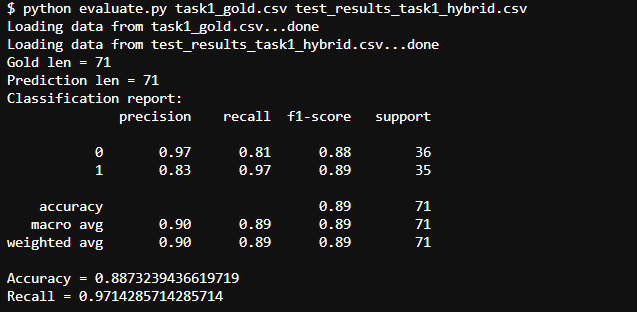